In [ ]:
import deep_models.config as c
from deep_models.data import load_folds, make_splits, S00MILDataset
from torch.utils.data import DataLoader
from deep_models.vae import ConvVAE
from deep_models.vae_train import init_model, fit, plot_history

In [ ]:
split_k = 7

In [ ]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1085  val=132  test=136


In [4]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True, return_cond=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False, return_cond=True)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [ ]:
model = ConvVAE(latent=64, cond_dim=2, cond_in_encoder=True).to(c.device)
init_model(model, train_loader)  

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=66, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=66, out_features=64, bias=True)
  (fc): Linear(in_features=66, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
)

# Train the model & save the best epoch's version

In [ ]:
history = fit(model,
              train_loader,
              val_loader,
              epochs=150,
              lr=1e-3,
              beta_max=5e-4,
              anneal_start=50,
              anneal_epochs=50,
              ckpt_path=f"best_cvae_split{split_k}.pt")

epoch   1/150  beta 0.00e+00  train 0.7642  val 0.6985  recon 0.6985  MSE 0.00051  KL 139.27  R2 0.095
epoch   2/150  beta 0.00e+00  train 0.5825  val 0.5238  recon 0.5238  MSE 0.00039  KL 311.76  R2 0.321
epoch   3/150  beta 0.00e+00  train 0.4822  val 0.4558  recon 0.4558  MSE 0.00034  KL 368.25  R2 0.410
epoch   4/150  beta 0.00e+00  train 0.4278  val 0.3957  recon 0.3957  MSE 0.00029  KL 451.81  R2 0.487
epoch   5/150  beta 0.00e+00  train 0.3587  val 0.3361  recon 0.3361  MSE 0.00025  KL 491.05  R2 0.564
epoch   6/150  beta 0.00e+00  train 0.3244  val 0.3146  recon 0.3146  MSE 0.00023  KL 485.50  R2 0.592
epoch   7/150  beta 0.00e+00  train 0.3085  val 0.3024  recon 0.3024  MSE 0.00022  KL 480.89  R2 0.608
epoch   8/150  beta 0.00e+00  train 0.2975  val 0.2910  recon 0.2910  MSE 0.00021  KL 474.29  R2 0.623
epoch   9/150  beta 0.00e+00  train 0.2859  val 0.2809  recon 0.2809  MSE 0.00021  KL 483.97  R2 0.636
epoch  10/150  beta 0.00e+00  train 0.2771  val 0.2741  recon 0.2741  MSE

# Evaluate training history

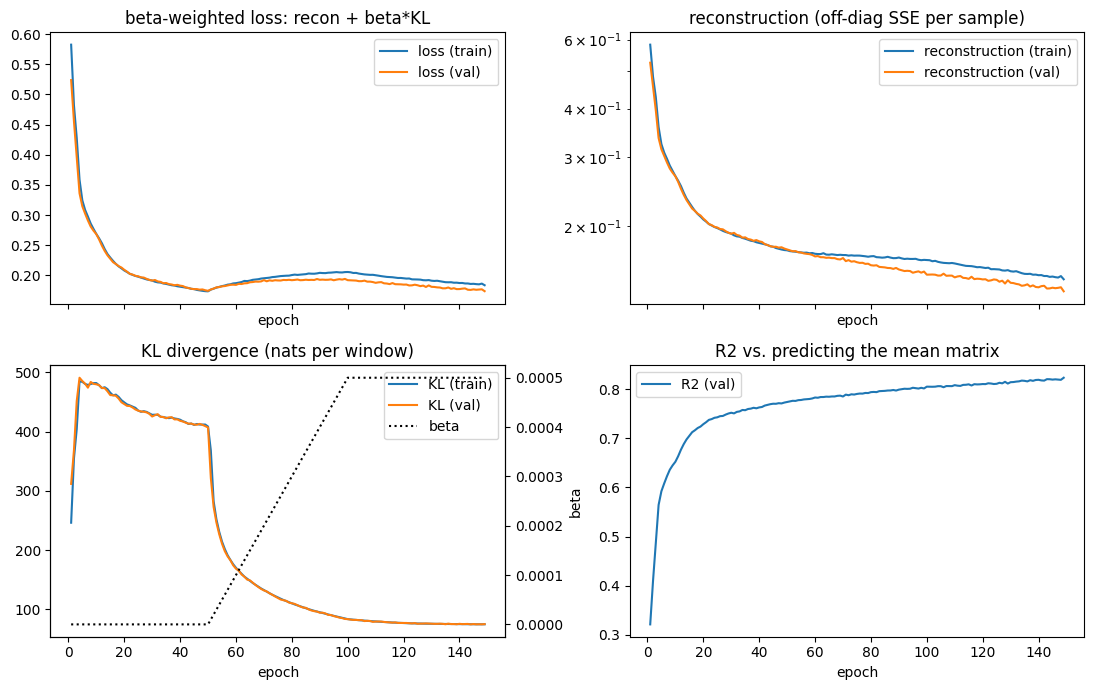

In [8]:
g = plot_history(history, skip=1)
g.show()